# Notebook 13: More Long/Short Strategies

**References:** Lehmann, B. N. (1990). Fads, martingales, and market efficiency. *Quarterly Journal of Economics* 105(1), 1-28. Lo, A. W. and MacKinlay, A. C. (1990). When are contrarian profits due to stock market overreaction? *Review of Financial Studies* 3(2), 175-205. Jegadeesh, N. and Titman, S. (1993). Returns to buying winners and selling losers: implications for stock market efficiency. *Journal of Finance* 48(1), 65-91. Hou, K. (2007). Industry information diffusion and the lead-lag effect in stock returns. *Review of Financial Studies* 20(4), 1113-1138. Cont, R., Kukanov, A. and Stoikov, S. (2014). The price impact of order book events. *Journal of Financial Econometrics* 12(1), 47-88. Gârleanu, N. and Pedersen, L. H. (2013). Dynamic trading with predictable returns and transaction costs. *Journal of Finance* 68(6), 2309-2340.

Notebook 12 traded relations among books: pairs, baskets and residuals, each a bet that a gap closes. This notebook tries other ways to be long and short in the same books, in four stages. The first, here, is four cross-sectional signals. Each scores every book at a rebalance, takes the scores less their projection on a vector of ones and on the books' exposures to the PCA factors, and holds lots in proportion to what is left: a book of longs and shorts whose weights have no exposure to the dollar or to the estimated factors (rounding to whole lots, and the errors of the estimates, leave the lots some: the exposure column of section 3 runs from 1.6 to 4.6 lots, root mean square, of exposure to the true factors for the new traders, against about 25 lots held). The signals are *reversal* (buy the books that fell: Lehmann 1990; Lo and MacKinlay 1990), *momentum* (buy those that rose: Jegadeesh and Titman 1993), *lead-lag* (buy those that the other books' last moves say will rise: Lo and MacKinlay 1990; Hou 2007) and *order flow* (buy those with the buying, in their trades or in their queues, after Cont, Kukanov and Stoikov 2014).

**The market** is notebook 12's (`lob/statarb.py`): twelve books whose fair values share common factors through a table of loadings, each with a part of its own that mean-reverts and is moved by order flow, and traders around each fair value whose orders the mids follow. The two tables are the same, *sectors* (a market factor and three sector factors) and *mixed* (three factors, with loadings in no order). A trader here takes out as many factors as its market's fair values share: three in each, the rank of the loadings (the sectors table has four columns, but its market column is the sum of its three sector columns).

**The conventions** are notebook 12's. Every trader is alone in its market, with market orders, and pays what crossing the spreads costs in the books. Every setting was chosen on seeds 1 to 8. Section 3's tables are on seeds 101 to 112, over 20,000 units of time after a warm-up, and section 4's cards on seed 101. Sections 1 and 2, which vary one thing, use seeds 101 to 108 and bare markets of 12,000 units of time, with no trader in them and none of the run discarded (section 2's listeners record only once their PCA window of 500 decisions has filled). The costs in section 2 come from one trader of each of four kinds, on seed 101, over 4,000 units of time after its warm-up and 400 more. P&L is after costs, in ticks x lots, with its standard error across seeds, and per unit of risk it is the mean change in a unit of time over their standard deviation. Every backtest has a scorecard and a signal chart.

In [1]:
import math
import sys

sys.path.insert(0, '..')
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from joblib import Parallel, delayed
from IPython.display import display
from quant_plots import Backtest, scorecard, signal_chart

from lob.analysis.plotting import set_style
from lob.crosssection import (
    FlowTrader,
    LeadLagTrader,
    MomentumTrader,
    ReversalTrader,
    contrarian_decomposition,
    estimate_factors,
    neutralize,
)
from lob.statarb import (
    BookMarket,
    FactorValues,
    RelationTrader,
    ResidualTrader,
    mixed_loadings,
    pairs_by_distance,
    score_portfolio,
    sector_loadings,
)

set_style()
BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'

SEEDS = range(101, 113)  # none of the settings below was chosen on these
FEW = range(101, 109)  # for the tables that vary one thing
EVERY = 5.0  # a trader decides this often, in units of time, unless it says otherwise
SPAN = 20_000.0
BARE = 12_000.0  # units of time of a market with no trader in it
# Each market's loadings and the number of factors its fair values share, the rank of the loadings: three in each (the
# sectors table's market column is the sum of its three sector columns).
MARKETS = {'sectors': (sector_loadings(3, 4), 3), 'mixed': (mixed_loadings(12, 3, seed=3), 3)}
COLUMNS = [
    'pnl',
    'se',
    'positive',
    'before_costs',
    'costs',
    'lots',
    'cost_a_lot',
    'entries',
    'gross',
    'exposure',
    'risk_adjusted',
]


def scored(make, loadings, seed, burn, span=SPAN):
    trader = make()
    market = BookMarket(FactorValues(loadings), seed=seed, traders=(trader,))
    return score_portfolio(market, trader, burn, span)


def compare(traders, burn, markets=MARKETS, seeds=SEEDS, span=SPAN):
    # Every trader alone in every market on every seed: the same span after the same warm-up. A trader is made
    # from the number of factors its market has.
    def row(market_name, name, seed):
        loadings, factors = markets[market_name]
        return {
            'market': market_name,
            'trader': name,
            'seed': seed,
            **scored(partial(traders[name], factors), loadings, seed, burn, span),
        }

    frame = pd.DataFrame(
        Parallel(n_jobs=-1)(
            delayed(row)(market_name, name, seed) for market_name in markets for name in traders for seed in seeds
        )
    )
    table = frame.groupby(['market', 'trader'], sort=False).agg(
        pnl=('pnl', 'mean'),
        se=('pnl', lambda p: p.std() / math.sqrt(len(p))),
        positive=('pnl', lambda p: f'{(p > 0).sum()} of {len(p)}'),
        before_costs=('before_costs', 'mean'),
        costs=('costs', 'mean'),
        lots=('lots', 'mean'),
        entries=('entries', 'mean'),
        gross=('gross', 'mean'),
        exposure=('exposure', 'mean'),
        risk_adjusted=('risk_adjusted', 'mean'),
    )
    table['cost_a_lot'] = table.costs / table.lots.replace(0, np.nan)
    return frame, table


def shown(table, *drop):
    return (
        table[[column for column in COLUMNS if column not in drop]]
        .round(
            {
                'pnl': 0,
                'se': 0,
                'before_costs': 0,
                'costs': 0,
                'lots': 0,
                'entries': 0,
                'gross': 1,
                'exposure': 1,
                'risk_adjusted': 3,
                'cost_a_lot': 2,
            }
        )
        .to_string()
    )


# Ticks x lots: more than the cards of section 4 hold at their most (each prints its peak as a multiple of it).
CAPITAL = 150_000.0


def record_of(trader):
    times, mids, held, signals = zip(*trader.history, strict=True)
    held = np.array(held)
    first = max(int(np.argmax(np.abs(held).sum(axis=1) > 0)) - 1, 0)
    days = pd.bdate_range('2026-01-01', periods=len(times) - first)
    columns = [f'book {i}' for i in range(held.shape[1])]
    prices = pd.DataFrame(np.array(mids)[first:], index=days, columns=columns)
    weights = pd.DataFrame(held[first:] * np.array(mids)[first:] / CAPITAL, index=days, columns=columns)
    returns = prices.pct_change().fillna(0.0)
    turnover = Backtest(weights, returns, cost_bp=0.0).turnover.sum() * CAPITAL
    cost_bp = trader.spread_paid / turnover * 1e4
    return Backtest(weights, returns, cost_bp=cost_bp), prices, weights, signals[first:], days, cost_bp, times[first:]


def card(
    trader,
    fills,
    strategy,
    detail,
    title,
    setting,
    signal_label,
    levels,
    relation,
    book,
    per_unit=5,
    start=200,
    end=900,
):
    bt, prices, weights, signals, days, cost_bp, times = record_of(trader)
    note = (
        f"Simulated: {setting}. A card day is one decision of the trader, {per_unit} unit"
        f"{'' if per_unit == 1 else 's'} of simulation time (252 make a card year); it trades at once, with market "
        f"orders in the books it changes. The record holds what it held after each decision, valued at the mids just "
        f"before its orders, on capital of {CAPITAL:,.0f} ticks x lots; its costs, {cost_bp:.1f} bp of the record's "
        f"turnover, add up to what crossing the spreads cost. Its fills "
        f"made {fills:+,.0f}, this record {bt.net.sum() * CAPITAL:+,.0f}. The record runs from the trader's first "
        f"order, at time {times[0]:,.0f}, to the end of the run, at {times[-1]:,.0f}; the tables count only the last "
        f"{SPAN:,.0f} units, so their figure for this trader differs."
    )
    # The library's note on the circles, which follows this footnote, is for a backtest that fills after it decides.
    chart_note = (
        f"The position is what the trader held after each decision, in ticks x lots: the weight times {CAPITAL:,.0f} "
        f"of capital. Marker area grows with the lots traded; re-sizing trades under a quarter of the window's largest "
        f"are not marked. The note on the circles that follows is the library's, for a backtest that fills after it "
        f"decides; here the record holds the position after each decision's own orders, so a circle sits on the step "
        f"it caused."
    )
    display(scorecard(bt, strategy, detail=detail, capital=CAPITAL, title=title, footnote=note))
    name = f'book {book}'
    signal = pd.Series([np.nan if s is None or len(s) <= relation else s[relation] for s in signals], index=days)
    held = weights[name]
    side, before = np.sign(held), np.sign(held).shift(fill_value=0)
    signal_chart(
        name,
        prices[name],
        held,
        signal,
        capital=CAPITAL,
        strategy=strategy,
        signal_label=signal_label,
        levels=levels,
        entries=list(days[((side != 0) & (side != before)).to_numpy()]),
        exits=list(days[((before != 0) & (side != before)).to_numpy()]),
        start=days[start],
        end=days[end],
        footnote=chart_note,
        asset_name='one of the twelve books it trades',
    )
    plt.show()
    return fills, bt.net.sum() * CAPITAL


def recorded(make, burn, market='sectors'):
    loadings, factors = MARKETS[market]
    trader = make(factors)
    trader.record = True
    book = BookMarket(FactorValues(loadings), seed=SEEDS[0], traders=(trader,))
    while book.time < burn + SPAN:
        book.step()
    return trader, trader.value(book.marks())

## 1. What the Moves Remember

Before trading anything, look at what the books' moves remember. Each signal is a bet on how a book's next move relates to its own past (reversal and momentum) or to the other books' (lead-lag), and the market's construction says what to expect. A mid follows its fair value a few units of time late, so a move should carry on a little at short horizons. A book's own part reverts with a half-life of 50 units, so over longer horizons some of what a book gained should be given back. The factors are random walks, with no memory, and the PCA takes them out of the moves. What is left, a book's residual, is mostly its own part, which is independent of the other books': a book's past should say little of another's future.

The test is a bare market for each market and seed, with no trader in it, run for 12,000 units of time with the mids sampled every unit. The residual moves are the one-unit moves less what three PCA factors, as many as the fair values share, take of them, as the library finds it. For each horizon $h$ the residual moves are added up in non-overlapping stretches of $h$ units. *Own* is the correlation of a book's sum with its next, averaged over the books; *cross* is the correlation of one book's sum with another book's next, averaged over ordered pairs of distinct books. Both are averaged over the seeds, with the standard error across seeds. *Cross* is not free of *own*, though. The PCA leaves residuals that sum to about 0 across the books (each in units of its standard deviation), so when a book's sum predicts its own next, the other books' sums must predict that book's next by about the opposite, shared among the other books: on average $-$own$/(n-1)$ for $n$ books. That is the *forced* value, the dashed line below, and it is exact if the books' standard deviations are equal. What the cross correlation shows beyond it, *beyond* (cross less forced), is the part that could be lead-lag. The lead-lag signal is tested directly in section 2. Last, Lo and MacKinlay's (1990) split of a contrarian portfolio's profit into the books' own autocovariances and their cross-autocovariances is computed at lags of 1, 5 and 25 units, on the moves before any factor is taken out.

Correlation of the residual moves summed over h units with the next h units; mean over seeds, and its se
Forced: what the PCA fixes the cross at, -own / (n - 1). Beyond: cross less forced.
                   own  own_se  cross  cross_se  forced  beyond  beyond_se
market  horizon                                                           
sectors 1       -0.159   0.002  0.014     0.000   0.014  -0.000        0.0
        2       -0.121   0.002  0.011     0.000   0.011  -0.000        0.0
        5       -0.013   0.003  0.001     0.000   0.001  -0.000        0.0
        10       0.038   0.005 -0.003     0.000  -0.003   0.000        0.0
        25      -0.045   0.004  0.004     0.000   0.004  -0.000        0.0
        50      -0.206   0.009  0.019     0.001   0.019  -0.000        0.0
        100     -0.344   0.006  0.031     0.001   0.031  -0.000        0.0
        200     -0.439   0.016  0.039     0.001   0.040  -0.000        0.0
mixed   1       -0.140   0.001  0.012     0.000   0.013  -0.0

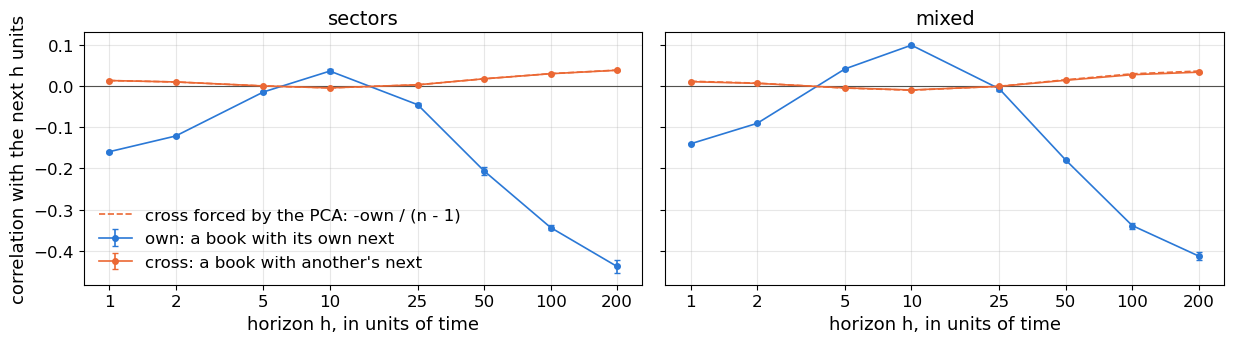


Profit of the contrarian portfolio a decision, in thousandths of a tick, and where it comes from (mean)
             profit     se     own   cross  means
market  lag                                      
sectors 1    45.052  1.631 -19.445  64.575 -0.078
        5   -24.317  0.999 -60.544  36.305 -0.078
        25    0.175  0.342  -4.018   4.269 -0.076
mixed   1    40.458  0.749  -2.635  43.124 -0.031
        5   -18.460  0.287 -41.937  23.508 -0.031
        25    0.075  0.603  -2.233   2.339 -0.031


In [2]:
HORIZONS = (1, 2, 5, 10, 25, 50, 100, 200)  # units of time
LAGS = (1, 5, 25)


def bare_moves(market, seed):
    # The one-unit moves of the mids in a market with no trader, and the same less what the true number of estimated
    # factors takes of them: (moves - mean) @ eigen @ betas, as the library does.
    loadings, factors = MARKETS[market]
    frame = BookMarket(FactorValues(loadings), seed=seed).run(BARE)
    moves = np.diff(frame.filter(like='mid_').ffill().to_numpy(float), axis=0)
    eigen, betas = estimate_factors(moves, factors)
    return moves, moves - (moves - moves.mean(axis=0)) @ eigen @ betas


def autocorrelations(residual, h):
    # The correlations of non-overlapping h-unit sums with the next: of a book's with its own next (own, the mean over
    # books), and of one book's with another's next (cross, the mean over ordered pairs of distinct books). The
    # residuals are orthogonal to the estimated factors, so they sum to about 0 across the books in units of their
    # standard deviations. That forces the cross correlations into a book's next to sum to minus its own: -own / (n - 1)
    # on average, and exactly if the books' standard deviations were equal. Cross less forced could be lead-lag.
    sums = residual[: len(residual) // h * h].reshape(-1, h, residual.shape[1]).sum(axis=1)
    n = sums.shape[1]
    c = np.corrcoef(sums[:-1], sums[1:], rowvar=False)[:n, n:]  # row i: book i's sum, column j: book j's next
    own, cross = np.trace(c) / n, (c.sum() - np.trace(c)) / (n * (n - 1))
    return own, cross, -own / (n - 1)


def remembered(market, seed):
    moves, residual = bare_moves(market, seed)
    memory_rows = []
    for h in HORIZONS:
        own, cross, forced = autocorrelations(residual, h)
        memory_rows.append(
            {
                'market': market,
                'seed': seed,
                'horizon': h,
                'own': own,
                'cross': cross,
                'forced': forced,
                'beyond': cross - forced,
            }
        )
    split_rows = [
        {'market': market, 'seed': seed, 'lag': lag, **contrarian_decomposition(moves, lag)} for lag in LAGS
    ]
    return memory_rows, split_rows


runs = Parallel(n_jobs=-1)(delayed(remembered)(market, seed) for market in MARKETS for seed in FEW)
memory = pd.DataFrame([row for rows, _ in runs for row in rows])
split = pd.DataFrame([row for _, rows in runs for row in rows])

by_horizon = memory.groupby(['market', 'horizon'], sort=False)[['own', 'cross', 'forced', 'beyond']]
memory_mean, memory_se = by_horizon.mean(), by_horizon.sem()
print('Correlation of the residual moves summed over h units with the next h units; mean over seeds, and its se')
print('Forced: what the PCA fixes the cross at, -own / (n - 1). Beyond: cross less forced.')
columns = ['own', 'own_se', 'cross', 'cross_se', 'forced', 'beyond', 'beyond_se']
print(memory_mean.join(memory_se, rsuffix='_se')[columns].round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6), sharey=True)
LINES = (('own', BLUE, 'own: a book with its own next'), ('cross', ORANGE, "cross: a book with another's next"))
for ax, market in zip(axes, MARKETS, strict=True):
    for column, color, label in LINES:
        ax.errorbar(
            HORIZONS,
            memory_mean.loc[market][column],
            yerr=memory_se.loc[market][column],
            color=color,
            marker='o',
            ms=4,
            lw=1.2,
            capsize=2,
            label=label,
        )
    ax.plot(
        HORIZONS,
        memory_mean.loc[market].forced,
        color=ORANGE,
        ls='--',
        lw=1.2,
        label='cross forced by the PCA: -own / (n - 1)',
    )
    ax.axhline(0, color=GRAY, lw=0.8)
    ax.set_xscale('log')
    ax.set_xticks(HORIZONS, [str(h) for h in HORIZONS])
    ax.minorticks_off()
    ax.set_title(market)
    ax.set_xlabel('horizon h, in units of time')
axes[0].set_ylabel('correlation with the next h units')
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()

by_lag = split.groupby(['market', 'lag'], sort=False)
decomposition = by_lag[['profit', 'own', 'cross', 'means']].mean()
decomposition.insert(1, 'se', by_lag.profit.sem())
print('\nProfit of the contrarian portfolio a decision, in thousandths of a tick, and where it comes from (mean)')
print((1000 * decomposition).round(3).to_string())

**A book's residual moves bounce, then continue, then revert.** Over one or two units of time a book's residual move and its next correlate negatively (-0.16 and -0.12 in the sectors market, -0.14 and -0.09 in the mixed): a mid that jumps with an order falls back as the book refills. Around 10 units they correlate positively (+0.04 in the sectors market, +0.10 in the mixed), as a mid follows its fair value a few units late. At 25 units they have reverted in the sectors market (-0.05) and not yet in the mixed (-0.01, se 0.005). From 50 units on they revert in both, more the longer the horizon (-0.21 and -0.18 at 50, -0.34 at 100 in both, -0.44 and -0.41 at 200), as each book's own part decays with its half-life of 50.

**Nothing passes between the books once the factors are out.** The cross-correlation is what the PCA forces, to within 0.003 at every horizon: a book's residual past says nothing of another's residual future.

**On raw moves, the contrarian portfolio lives on the factors catching up.** Lo and MacKinlay's portfolio on one-unit moves with a lag of 1 makes +45 thousandths of a tick a decision in the sectors market (se 1.6) and +40 in the mixed (se 0.7), more than all of it from the cross part (+65 and +43): with the factors in them, one book's move foretells the others' as their mids catch up. Its own part is negative (-19 and -3): a book's raw moves continue. With a lag of 5 it loses (-24 and -18), and with a lag of 25 it makes nothing (+0.2 and +0.1, se 0.3 and 0.6). These are profits of a portfolio with weights of 1/n, before any cost.

## 2. Do the Signals Know Anything?

A signal can know something and still lose to what trading it costs, so first ask what each signal knows, apart from the trading. The test is a *listener*: a trader of each kind in a bare market with a size so small that its lots round to zero, so that it never trades and the market is untouched (the cell checks that every listener's lots stay at 0). At each decision it records the factor-neutral weights it would hold. Two measures of what they know, over the next decision:

- The **edge** is the paper P&L of the weights over the next decision, per gross lot held (the sum of the weights' absolute values), in ticks.
- The **IC** is the correlation across the books of the weights with the books' next moves, averaged over decisions.

Fourteen listeners share each bare market, which is run for the same 12,000 units of time on the same eight seeds as in section 1. *Every* is the interval between a listener's decisions, in units of time, and it records its weights at each. The edge is earned on the lots held for a decision, but a signal that changes pays to trade the change, so it is set against what a lot traded costs. The **turnover** is the lots a listener trades at a decision per gross lot it holds, on average: the sum over books of the change in each weight as a share of the gross, which is 2 if the weights turn over in full and less if they carry on. The **edge per lot traded** is the edge over the turnover, the most a lot traded could cost for the signal to pay. For comparison, what a lot traded costs: one trader of each of four kinds (reversal with look back 5, momentum with 20, lead-lag and the queues; not trade flow) that rebalances at every decision of 5 units, in a market of its own on seed 101, over 4,000 units of time after its warm-up, and what it paid to cross the spreads for each lot it traded. A round trip of a lot, twice that, is the hurdle for a decision only if the weights turn over in full.

Lots traded by the 14 listeners, in 16 runs of a bare market: 0

Edge: ticks a gross lot held a decision. Turnover: lots traded a decision, a gross lot held. Per lot: edge per lot traded, in ticks.
IC: correlation with the next move. Mean over seeds, and its se.
                                                 edge  edge_se  turnover  per_lot  per_lot_se     ic  ic_se  decisions
market  listener                                                                                                      
sectors reversal, look back 1, every 1         0.1051   0.0012      1.49    0.070       0.001  0.104  0.001    11444.0
        reversal, look back 1, every 5         0.0054   0.0052      1.39    0.004       0.004 -0.008  0.002     1897.0
        reversal, look back 5, every 5        -0.0283   0.0041      0.61   -0.046       0.007 -0.020  0.002     1897.0
        reversal, look back 20, every 5        0.0946   0.0041      0.35    0.268       0.010  0.044  0.002     1897.0
        momentum, look 

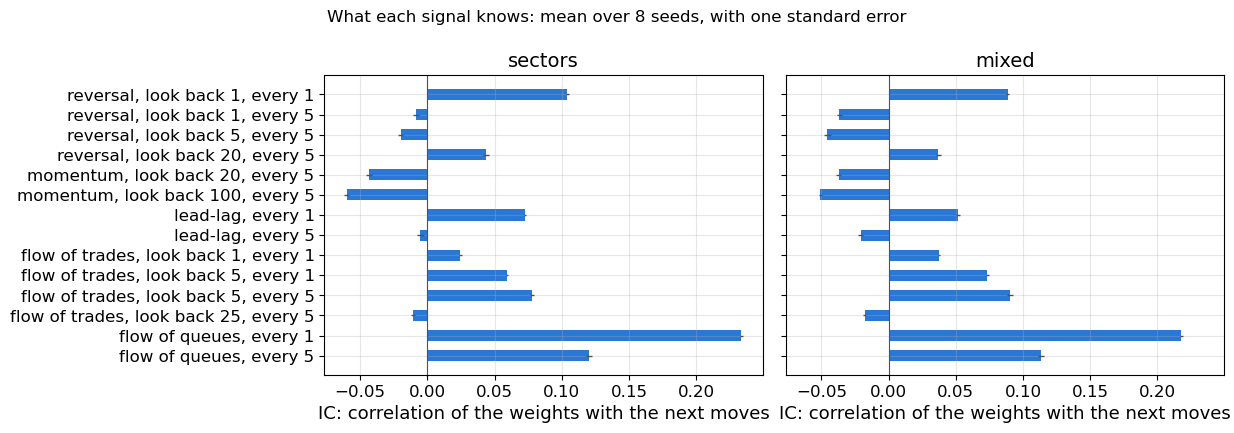


What crossing the spreads cost, in ticks a lot traded, for a trader that rebalances at every decision
                         lots  cost_a_lot
market  kind                             
sectors reversal        12614        1.12
        momentum         7513        1.02
        lead-lag        26910        1.30
        flow of queues  28009        1.36
mixed   reversal        11876        1.08
        momentum         6460        0.98
        lead-lag        26249        1.24
        flow of queues  27613        1.34


In [3]:
TINY = 1e-6  # lots of the largest leg: so few that every lot rounds to 0
LISTENERS = {  # name: kind, interval and settings (the weights are those of a rebalance at every decision)
    'reversal, look back 1, every 1': (ReversalTrader, 1.0, dict(lookback=1)),
    'reversal, look back 1, every 5': (ReversalTrader, 5.0, dict(lookback=1)),
    'reversal, look back 5, every 5': (ReversalTrader, 5.0, dict(lookback=5)),
    'reversal, look back 20, every 5': (ReversalTrader, 5.0, dict(lookback=20)),
    'momentum, look back 20, every 5': (MomentumTrader, 5.0, dict(lookback=20)),
    'momentum, look back 100, every 5': (MomentumTrader, 5.0, dict(lookback=100)),
    'lead-lag, every 1': (LeadLagTrader, 1.0, dict(lookback=1)),
    'lead-lag, every 5': (LeadLagTrader, 5.0, dict(lookback=1)),
    'flow of trades, look back 1, every 1': (FlowTrader, 1.0, dict(lookback=1)),
    'flow of trades, look back 5, every 1': (FlowTrader, 1.0, dict(lookback=5)),
    'flow of trades, look back 5, every 5': (FlowTrader, 5.0, dict(lookback=5)),
    'flow of trades, look back 25, every 5': (FlowTrader, 5.0, dict(lookback=25)),
    'flow of queues, every 1': (FlowTrader, 1.0, dict(lookback=1, measure='queues')),
    'flow of queues, every 5': (FlowTrader, 5.0, dict(lookback=1, measure='queues')),
}


def listener(kind, interval, settings, factors):
    # A trader of this kind that keeps, at each decision it rebalances at, the mids and the weights it would hold.
    class Listening(kind):
        def __post_init__(self):
            super().__post_init__()
            self.log = []

        def decide(self, mids):
            before = self._since
            moves = super().decide(mids)
            if self._since > before:
                self.log.append((mids.copy(), neutralize(self._scores, self._betas if self.factors else None)))
            return moves

    return Listening(size=TINY, interval=interval, hold=1, factors=factors, **settings)


def listen(market, seed):
    loadings, factors = MARKETS[market]
    traders = {name: listener(*spec, factors) for name, spec in LISTENERS.items()}
    book = BookMarket(FactorValues(loadings), seed=seed, traders=tuple(traders.values()))
    while book.time < BARE:
        book.step()
    rows = []
    for name, trader in traders.items():
        mids = np.array([m for m, _ in trader.log])
        weights = np.array([w for _, w in trader.log])[:-1]
        moves = np.diff(mids, axis=0)  # over the next decision
        gross = np.abs(weights).sum(axis=1)
        w, m = weights[gross > 0], moves[gross > 0]
        held = w / gross[gross > 0][:, None]  # the weights as shares of the gross lots held
        centered_w, centered_m = w - w.mean(axis=1, keepdims=True), m - m.mean(axis=1, keepdims=True)
        scale = np.sqrt((centered_w**2).sum(axis=1) * (centered_m**2).sum(axis=1))
        ic = (centered_w * centered_m).sum(axis=1)[scale > 0] / scale[scale > 0]
        edge = ((w * m).sum(axis=1) / gross[gross > 0]).mean()
        turnover = np.abs(np.diff(held, axis=0)).sum(axis=1).mean()  # lots traded a decision, a gross lot held
        rows.append(
            {
                'market': market,
                'seed': seed,
                'listener': name,
                'edge': edge,
                'turnover': turnover,
                'per_lot': edge / turnover,
                'ic': ic.mean(),
                'decisions': len(w),
                'lots': trader.lots,
            }
        )
    return rows


heard = pd.DataFrame(
    [row for rows in Parallel(n_jobs=-1)(delayed(listen)(m, s) for m in MARKETS for s in FEW) for row in rows]
)
assert (heard.lots == 0).all(), 'a listener traded'
runs_heard = len(heard) // len(LISTENERS)
print(f'Lots traded by the {len(LISTENERS)} listeners, in {runs_heard} runs of a bare market: {heard.lots.sum()}')
by_listener = heard.groupby(['market', 'listener'], sort=False)
knows = pd.DataFrame(
    {
        'edge': by_listener.edge.mean(),
        'edge_se': by_listener.edge.sem(),
        'turnover': by_listener.turnover.mean(),
        'per_lot': by_listener.per_lot.mean(),
        'per_lot_se': by_listener.per_lot.sem(),
        'ic': by_listener.ic.mean(),
        'ic_se': by_listener.ic.sem(),
        'decisions': by_listener.decisions.mean(),
    }
)
print(
    '\nEdge: ticks a gross lot held a decision. Turnover: lots traded a decision, a gross lot held. Per lot: edge per '
    'lot traded, in ticks.\nIC: correlation with the next move. Mean over seeds, and its se.'
)
print(
    knows.round(
        {'edge': 4, 'edge_se': 4, 'turnover': 2, 'per_lot': 3, 'per_lot_se': 3, 'ic': 3, 'ic_se': 3, 'decisions': 0}
    ).to_string()
)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), sharex=True, sharey=True)
for ax, market in zip(axes, MARKETS, strict=True):
    rows = knows.loc[market]
    place = np.arange(len(rows))[::-1]
    ax.barh(place, rows.ic, xerr=rows.ic_se, height=0.55, color=BLUE, error_kw=dict(ecolor=GRAY, lw=1))
    ax.axvline(0, color=GRAY, lw=0.8)
    ax.set_yticks(place, rows.index)
    ax.set_title(market)
    ax.set_xlabel('IC: correlation of the weights with the next moves')
fig.suptitle(f'What each signal knows: mean over {len(FEW)} seeds, with one standard error', fontsize=12)
fig.tight_layout()
plt.show()

# What crossing the spreads costs a lot: one trader of each kind, 5 lots of the largest, rebalancing at every decision.
COSTING = {
    'reversal': (ReversalTrader, dict(lookback=5)),
    'momentum': (MomentumTrader, dict(lookback=20)),
    'lead-lag': (LeadLagTrader, dict(lookback=1)),
    'flow of queues': (FlowTrader, dict(lookback=1, measure='queues')),
}


def costing(market, name):
    loadings, factors = MARKETS[market]
    kind, settings = COSTING[name]
    trader = kind(size=5.0, interval=EVERY, hold=1, factors=factors, **settings)
    got = scored(lambda: trader, loadings, FEW[0], trader.warm_up + 400.0, 4_000.0)
    return {'market': market, 'kind': name, 'lots': got['lots'], 'cost_a_lot': got['costs'] / got['lots']}


crossing = pd.DataFrame(Parallel(n_jobs=-1)(delayed(costing)(m, name) for m in MARKETS for name in COSTING))
print('\nWhat crossing the spreads cost, in ticks a lot traded, for a trader that rebalances at every decision')
print(crossing.set_index(['market', 'kind']).round({'lots': 0, 'cost_a_lot': 2}).to_string())

**Every signal knows something, at its own horizon.** In a market none of them trades, the queue imbalance knows most: its weights correlate 0.23 and 0.22 with the next unit's moves, and 0.12 and 0.11 with the next five. Trade flow over the last 5 decisions knows some (0.06 to 0.09). Reversal knows something one unit ahead (0.10 and 0.09) and over 20 decisions of five units (0.04), but not in between, where moves continue. Momentum knows the opposite of reversal, as it must here: -0.04 to -0.06. Lead-lag knows something one unit ahead (0.07 and 0.05) and nothing, or a little less, five ahead. Section 1 found nothing passing between the books once the factors are out, so what its factor-neutral weights know is most likely the last move's bounce seen through the other books' moves, which stand in for minus a book's own when the residuals add to about nothing.

**What they know is small against what trading it costs.** Rebalanced at every decision of five units, the best, trade flow over 5 decisions, earns 0.31 and 0.33 ticks a lot traded, against the 1.21 and 1.15 a lot that trading it costs in section 3. The queue imbalance, deciding every five units like the trader costed beside it, earns 0.17 and 0.15 a lot traded, about an eighth of what a lot costs it (1.36 and 1.34, the most of the four kinds costed). So no signal here pays at the turnover of a rebalance at every decision. A signal held longer earns over more decisions for each lot traded, which is how a slow reversal can pay where this figure says no: section 3 tries that.

## 3. Can They Be Traded?

Each kind alone in its market, with market orders, after the same warm-up, over 20,000 units of time on the twelve seeds. A trader decides every 1 or every 5 units of time (*every*) and rebalances every *hold* decisions, with 5 lots of the largest book. Its settings are from small grids looked at on seeds 1 to 8, and every trader is neutral to three estimated factors, as many as the fair values share. The baselines are two traders of notebook 12 with the settings found there: eight pairs chosen by distance, and stat-arb on PCA residuals. The burn is the same for all: the longest warm-up among them, the baselines included, and 400 units of time more. That is a little longer than notebook 12's, so the baselines differ a little from its table. The settings were fixed in advance, from seeds 1 to 8, so the tables below are on seeds that chose none of them; a count of settings that earn more than two standard errors is a count over that fixed list, not a test, and the best of a kind is the best of the few tried, on these seeds.

                                                             pnl     se  positive  before_costs     costs      lots  cost_a_lot  entries  gross  exposure  risk_adjusted
market  trader                                                                                                                                                          
sectors reversal, look back 20, hold 100, every 5          968.0  106.0  12 of 12        2779.0    1811.0    1439.0        1.26    240.0   25.2       1.7          0.007
        reversal, look back 5, hold 20, every 5          -4137.0  237.0   0 of 12        5098.0    9236.0    7265.0        1.27   1211.0   25.1       1.6         -0.025
        reversal, look back 1, hold 5, every 5          -36214.0  318.0   0 of 12         791.0   37005.0   28326.0        1.31   4704.0   24.9       1.6         -0.166
        momentum, look back 100, hold 100, every 5       -5087.0  137.0   0 of 12       -2916.0    2170.0    1706.0        1.27    294.0   25.5       1.7  

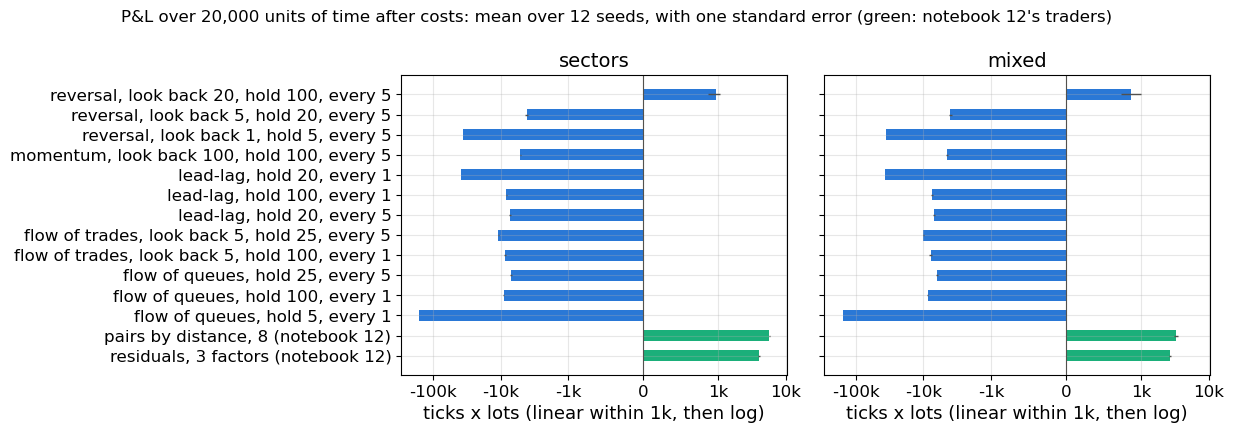

In [4]:
FORMATION = 2_000  # the decisions' mids a trader of notebook 12 chooses its pairs from: 10,000 units of time
Z = dict(window=400, entry=2.0, interval=EVERY, formation=FORMATION)  # a window of 2,000 units of time
RESIDUAL_BEST = dict(window=400, open_at=1.5, close_long=0.0, close_short=0.0)


def cross_section(kind, **settings):
    # A trader of this kind with 5 lots of the largest, made for the number of factors its market has.
    return lambda factors: kind(size=5.0, factors=factors, **settings)


TRADERS = {
    'reversal, look back 20, hold 100, every 5': cross_section(ReversalTrader, lookback=20, hold=100, interval=5.0),
    'reversal, look back 5, hold 20, every 5': cross_section(ReversalTrader, lookback=5, hold=20, interval=5.0),
    'reversal, look back 1, hold 5, every 5': cross_section(ReversalTrader, lookback=1, hold=5, interval=5.0),
    'momentum, look back 100, hold 100, every 5': cross_section(MomentumTrader, lookback=100, hold=100, interval=5.0),
    'lead-lag, hold 20, every 1': cross_section(LeadLagTrader, lookback=1, hold=20, interval=1.0),
    'lead-lag, hold 100, every 1': cross_section(LeadLagTrader, lookback=1, hold=100, interval=1.0),
    'lead-lag, hold 20, every 5': cross_section(LeadLagTrader, lookback=1, hold=20, interval=5.0),
    'flow of trades, look back 5, hold 25, every 5': cross_section(FlowTrader, lookback=5, hold=25, interval=5.0),
    'flow of trades, look back 5, hold 100, every 1': cross_section(FlowTrader, lookback=5, hold=100, interval=1.0),
    'flow of queues, hold 25, every 5': cross_section(FlowTrader, lookback=1, hold=25, interval=5.0, measure='queues'),
    'flow of queues, hold 100, every 1': cross_section(
        FlowTrader, lookback=1, hold=100, interval=1.0, measure='queues'
    ),
    'flow of queues, hold 5, every 1': cross_section(FlowTrader, lookback=1, hold=5, interval=1.0, measure='queues'),
}
BASELINES = {
    'pairs by distance, 8 (notebook 12)': lambda factors: RelationTrader(
        choose=partial(pairs_by_distance, count=8), size=2.5, **Z
    ),
    'residuals, 3 factors (notebook 12)': lambda factors: ResidualTrader(
        factors=3, interval=EVERY, size=5.0, **RESIDUAL_BEST
    ),
}
EVERYONE = {**TRADERS, **BASELINES}
BURN = max(make(3).warm_up for make in EVERYONE.values()) + 400.0

# The before-cost column adds back what crossing the spreads cost. At high turnover it also holds the trader's own
# impact on the mid it is marked at: its buys move the book's mid up, and it is marked at the new mid. A review of the
# library found that this can be nearly all of the before-cost figure, so the column is not the worth of a signal;
# section 2 measures that without trading.
frame, table = compare(EVERYONE, BURN)
print(shown(table))
print(
    "\nBefore costs is P&L with what crossing the spreads cost added back. At high turnover it also holds the trader's "
    "own impact on the mid it is marked at,\nand so is not the worth of its signal: section 2 measures that without "
    'trading. Entries are books newly held long or short (relations entered, for the baselines).'
)
print(
    f"The burn is {BURN:,.0f} units of time, {BURN - (FORMATION * EVERY + 400.0):,.0f} more than notebook 12's, so the "
    "baselines differ a little from its table."
)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), sharex=True, sharey=True)
for ax, name in zip(axes, MARKETS, strict=True):
    rows = table.loc[name]
    place = np.arange(len(rows))[::-1]
    colors = [AQUA if trader in BASELINES else BLUE for trader in rows.index]
    ax.barh(place, rows.pnl, xerr=rows.se, height=0.55, color=colors, error_kw=dict(ecolor=GRAY, lw=1))
    ax.axvline(0, color=GRAY, lw=0.8)
    ax.set_yticks(place, rows.index)
    ax.set_title(name)
    ax.set_xlabel('ticks x lots (linear within 1k, then log)')
    ax.set_xscale('symlog', linthresh=1_000)  # since some lose a hundred times what others make
    ax.set_xticks([-100_000, -10_000, -1_000, 0, 1_000, 10_000])
    ax.minorticks_off()
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x / 1000:,.0f}k' if x else '0'))
fig.suptitle(
    f'P&L over {SPAN:,.0f} units of time after costs: mean over {len(SEEDS)} seeds, with one standard error '
    "(green: notebook 12's traders)",
    fontsize=12,
)
fig.tight_layout()
plt.show()

**Only the slow reversal pays, and little.** Over 20,000 units, reversal over 20 decisions, rebalanced every 100, makes +968 (se 106) in the sectors market and +868 (se 138) in the mixed, on 12 and 11 of the 12 seeds: a sixth and a quarter of what eight pairs make (+5,706 and +3,283), for fewer lots (1,439 against 2,387 in the sectors market). It was the best of the three reversal settings on seeds 1 to 8 as well, where it was chosen. Every other setting loses, in both markets and on every seed.

**The faster the same signal is traded, the more it loses.** The queue imbalance rebalanced every 5 decisions of one unit loses 162,450 in the sectors market: 141,273 lots at 1.40 a lot, against +35,156 before costs, a figure that at this turnover holds its own orders' push on the mids it is marked at, and so says little of the signal (section 2 measures that). Held for 100 decisions of one unit, it trades a nineteenth of the lots and loses 9,047, what it makes before costs (+1,168) being a ninth of its costs. Lead-lag held for 20 decisions of one unit loses 38,679, and for 100 decisions 8,196. Trade flow, tried at two settings only, loses about as much at either (10,798 and 8,549).

**Momentum loses, as it must here.** It loses 5,087 and 4,459, and before costs as well (-2,916 and -2,466): over its 100 decisions of five units the books' residuals revert, and the factors, random walks, have nothing to continue.

**So in these books, the cross-sectional signals are too fast or too weak for market orders.** What could change that is trading less for the same signal: going part of the way to the target, with a band inside which it does not trade (Gârleanu and Pedersen 2013). That is the next stage.

## 4. In a Backtest's Terms

The scorecard and signal chart of each new kind, in the sectors market, on seed 101, which played no part in choosing any setting. Reversal, momentum, lead-lag and the flow of the queues are at the dashboard's default look back, hold and interval; the flow of the trades, which the dashboard offers as the other reading of the flow, is at look back 5, hold 25 and interval 5. They are the traders of the previous section's table, so each is neutral to three factors, as the dashboard's are. As in notebooks 10 to 12, the record has one row per decision: what the trader held after it, valued at the mids just before its orders, with costs that add up to what crossing the spreads cost. The signal chart shows one book, one that the trader changes often, with that book's raw score and a line at a score of 0. The trader holds its weights, the scores less their projection on the ones and the factors, so it can be long a book whose score is under 0.

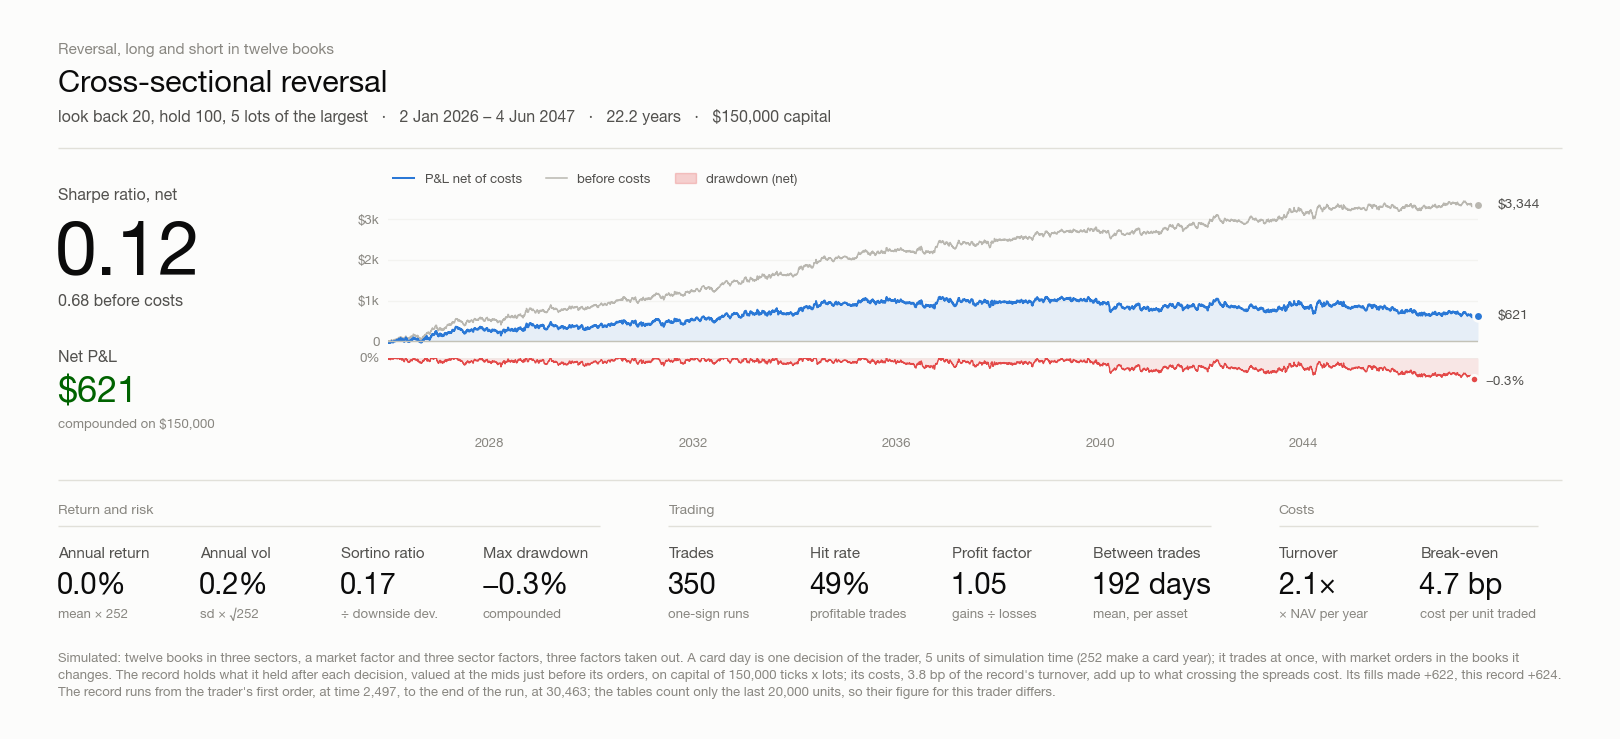

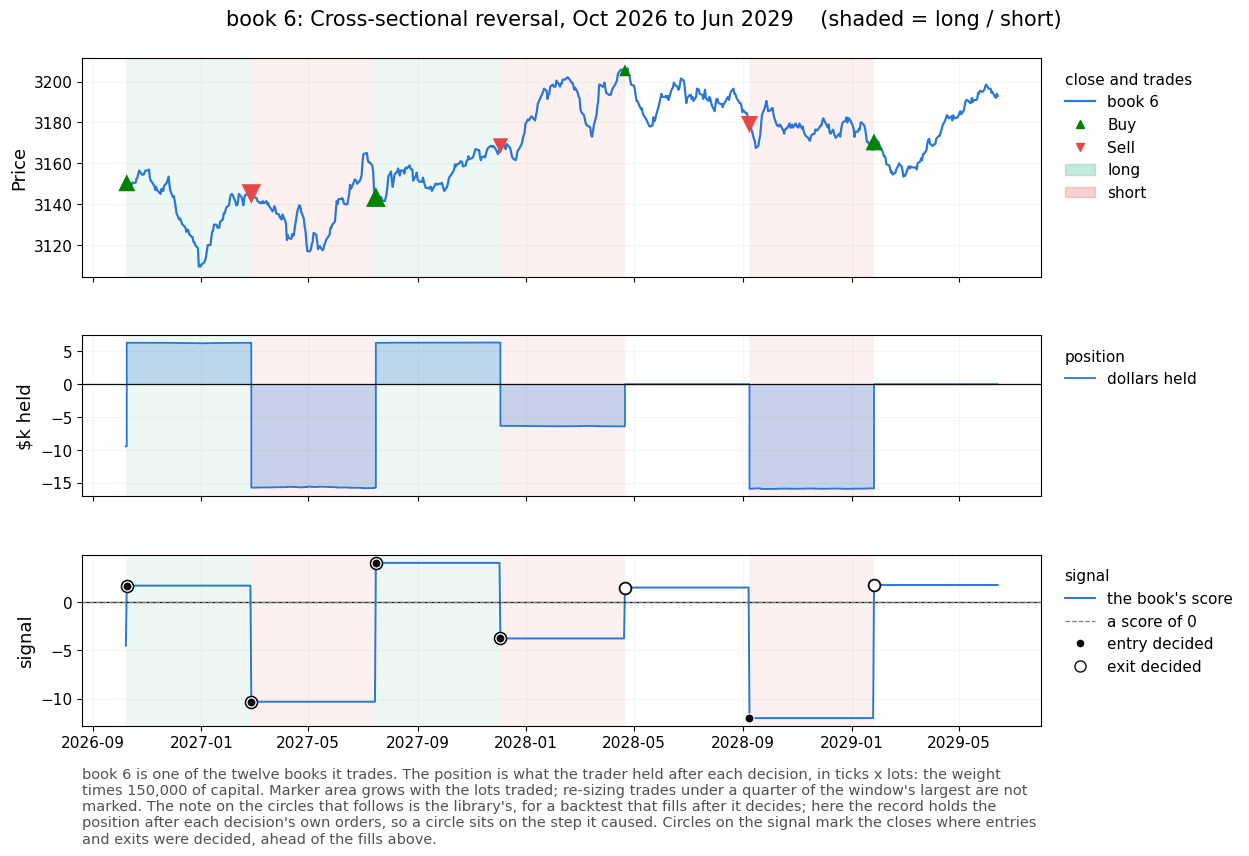

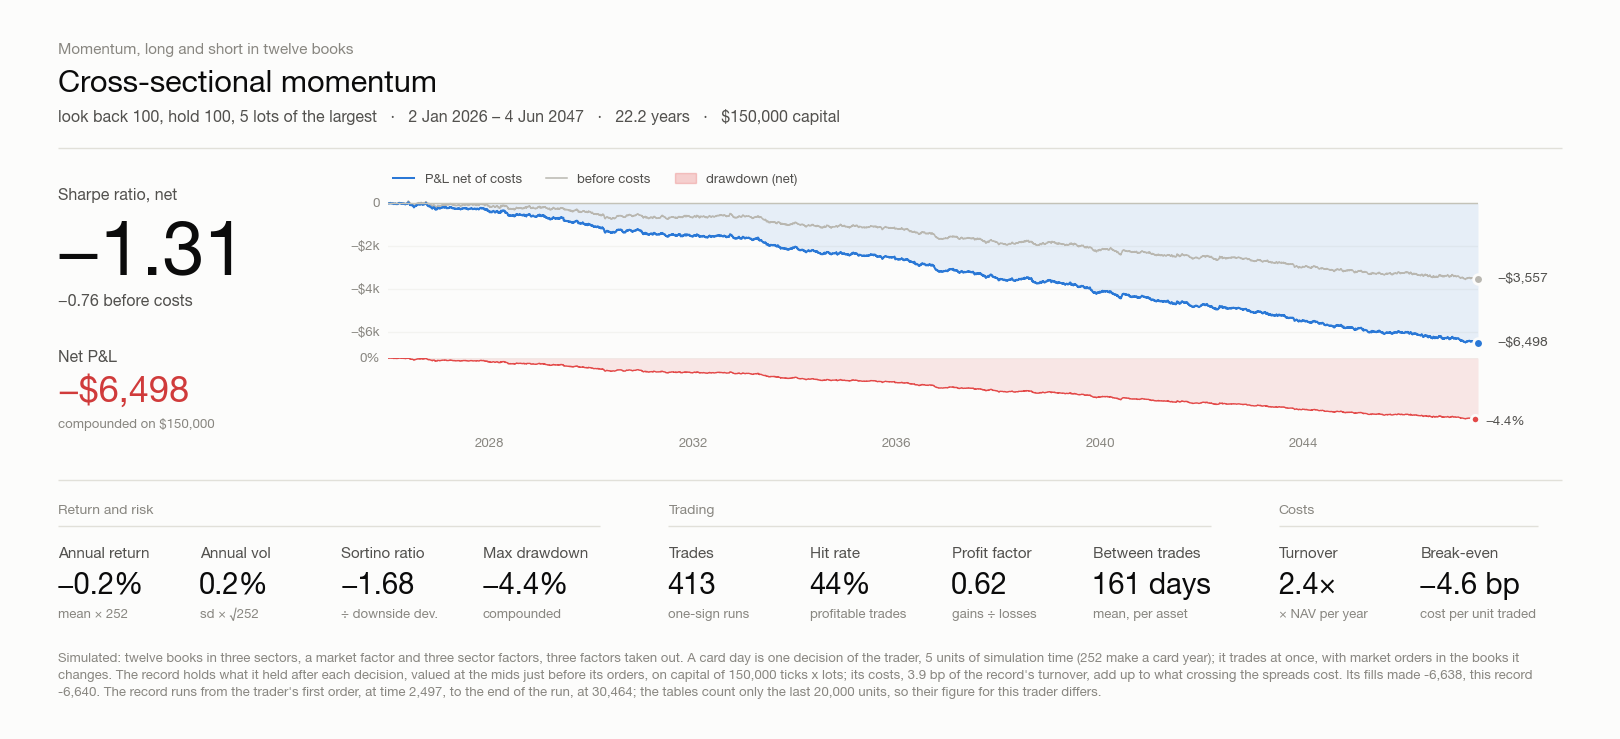

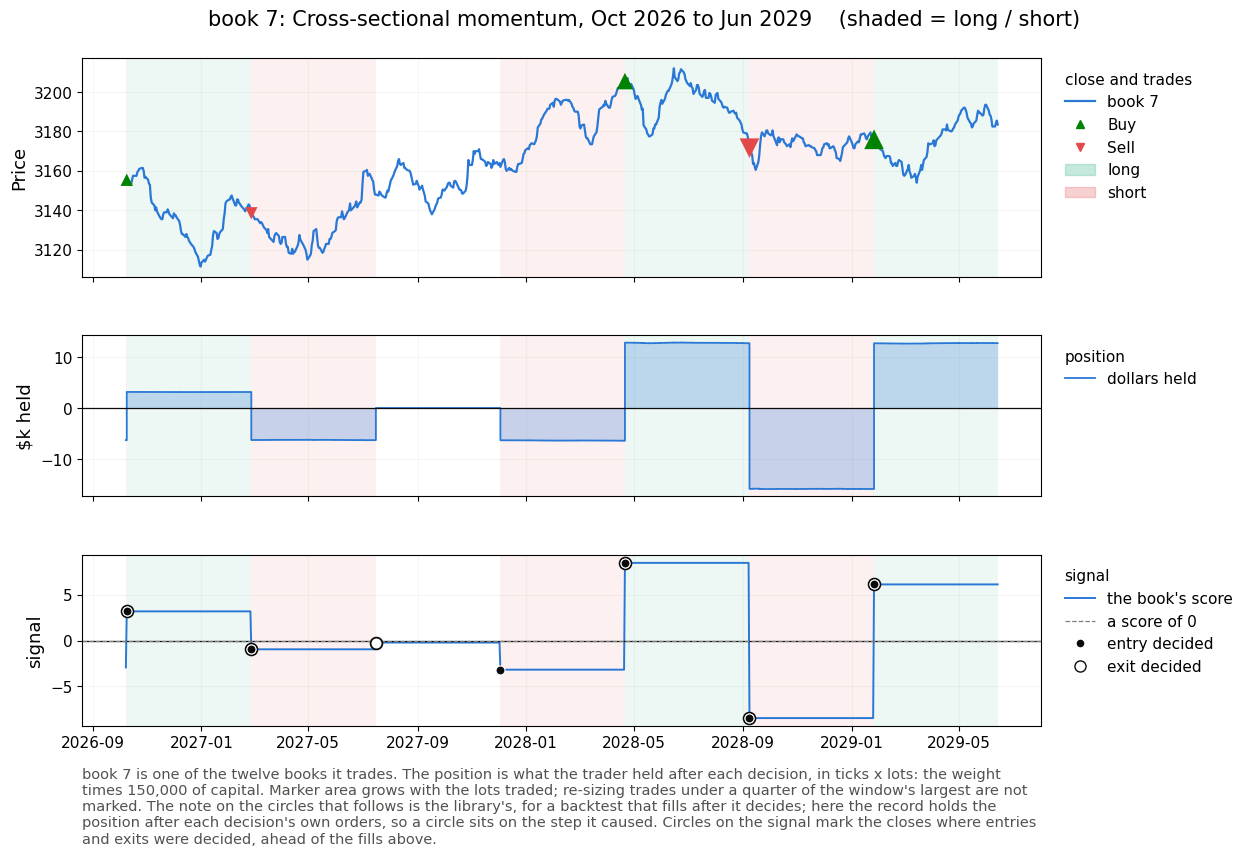

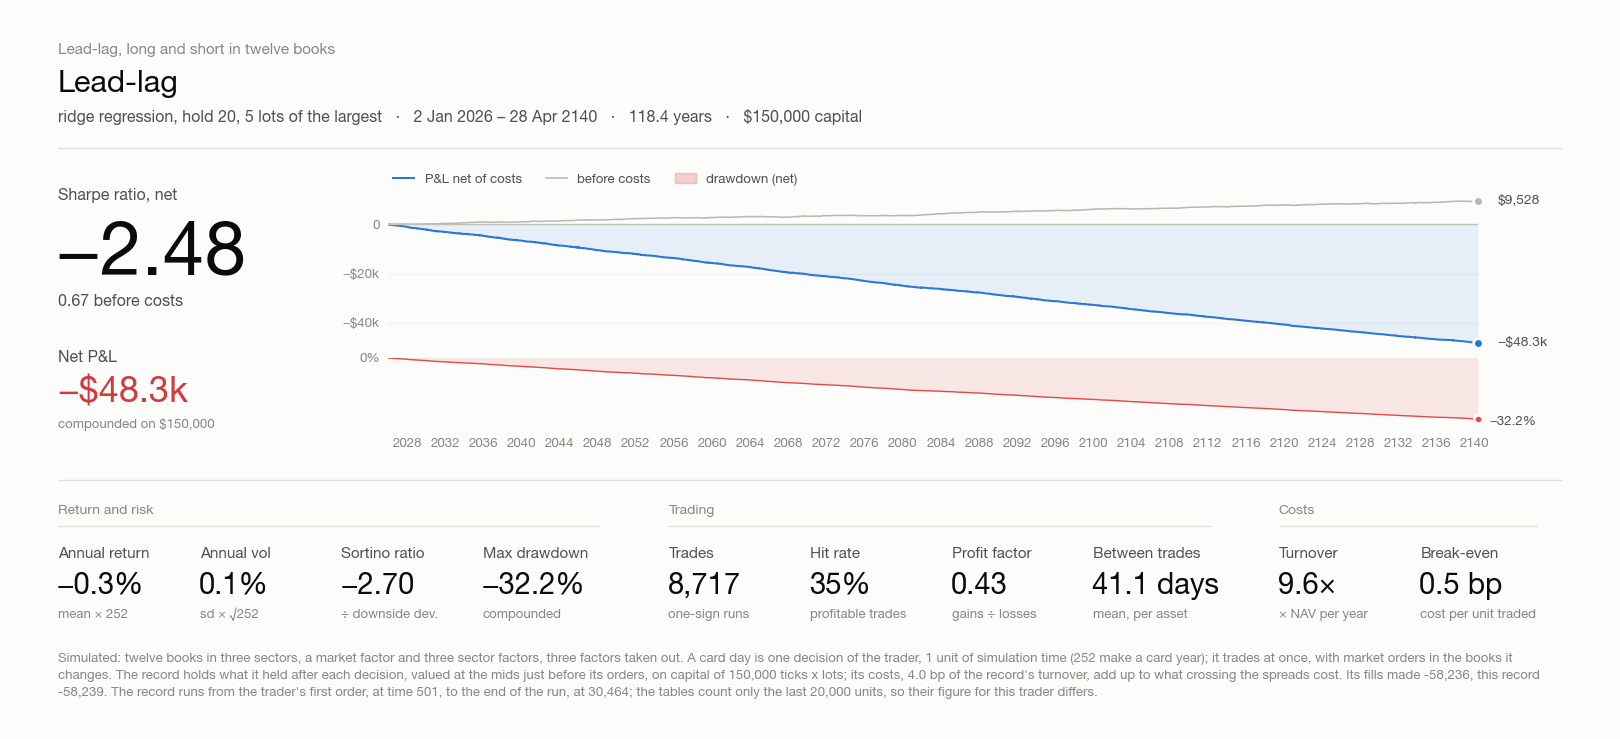

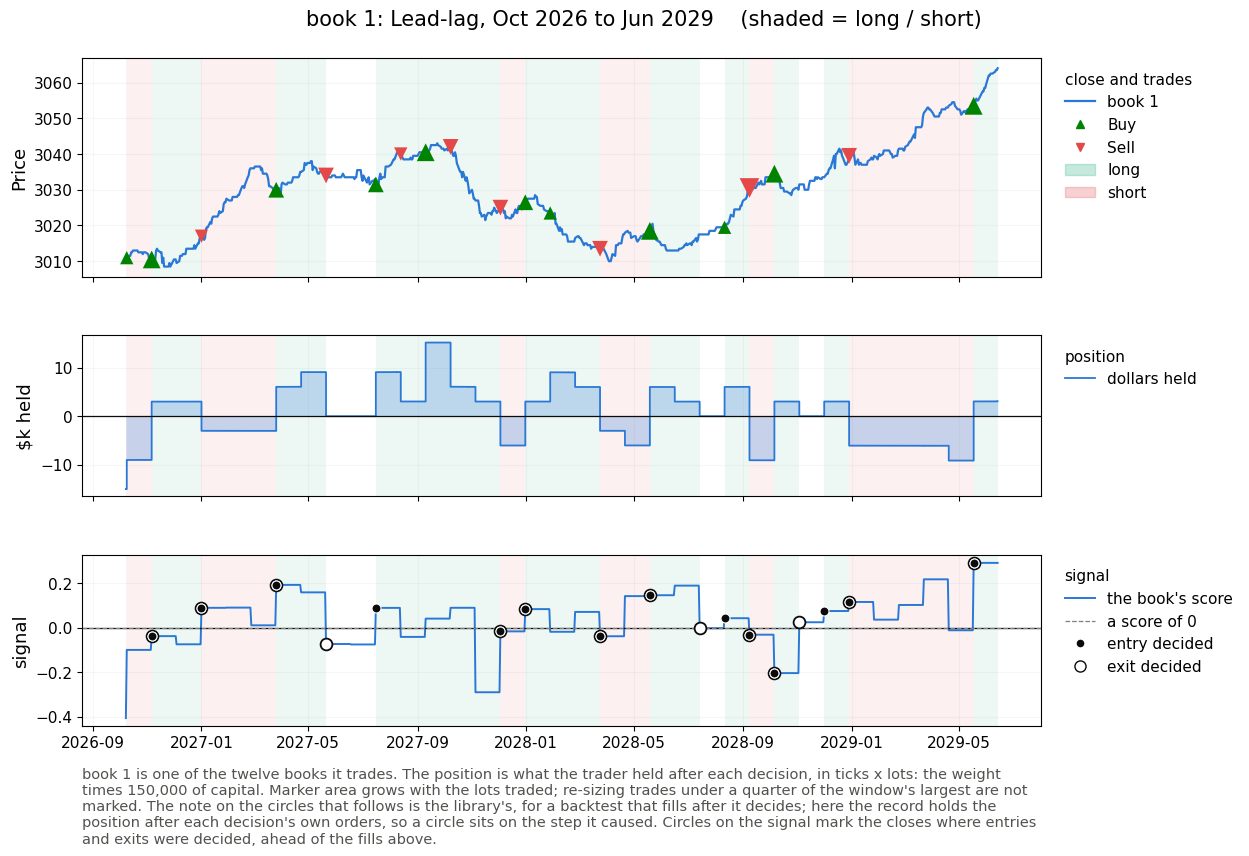

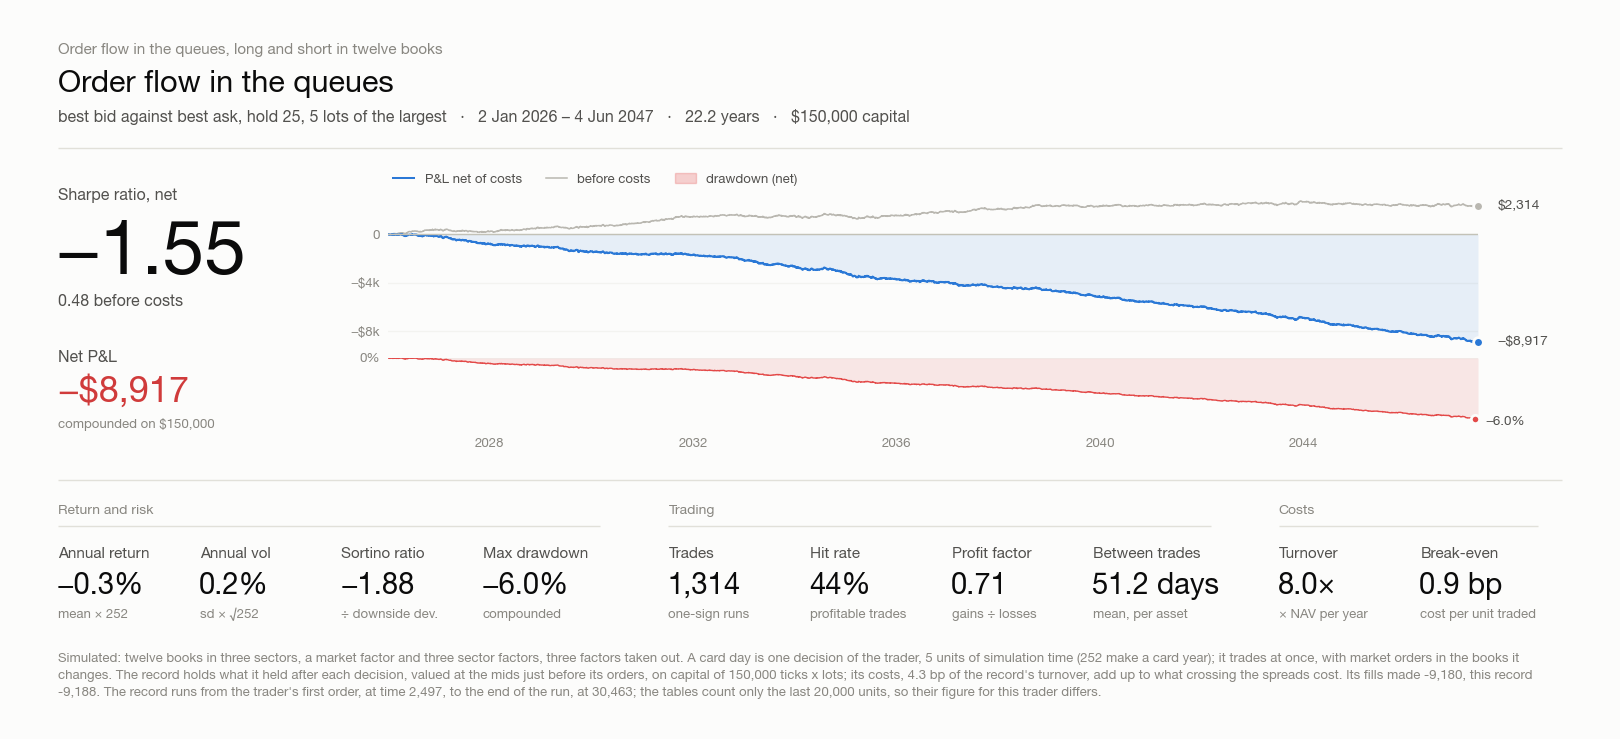

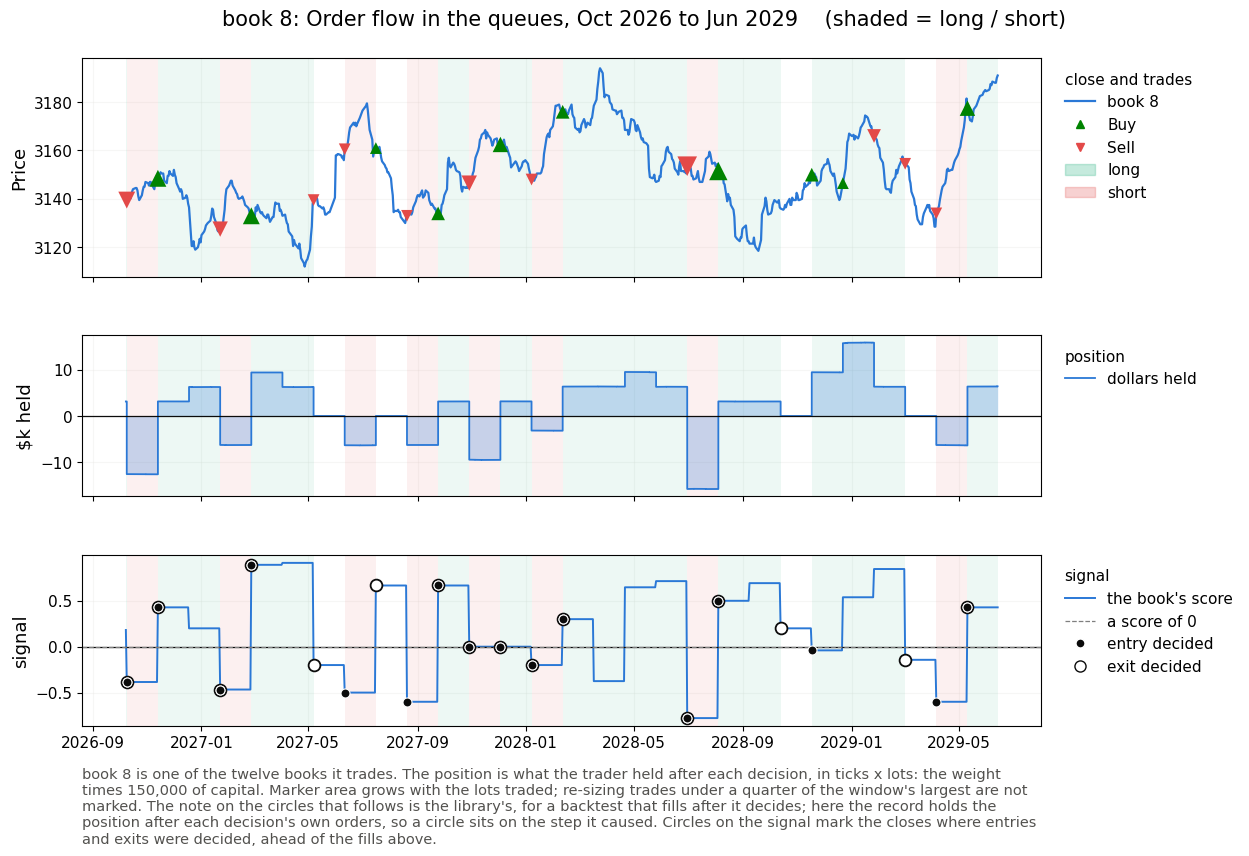

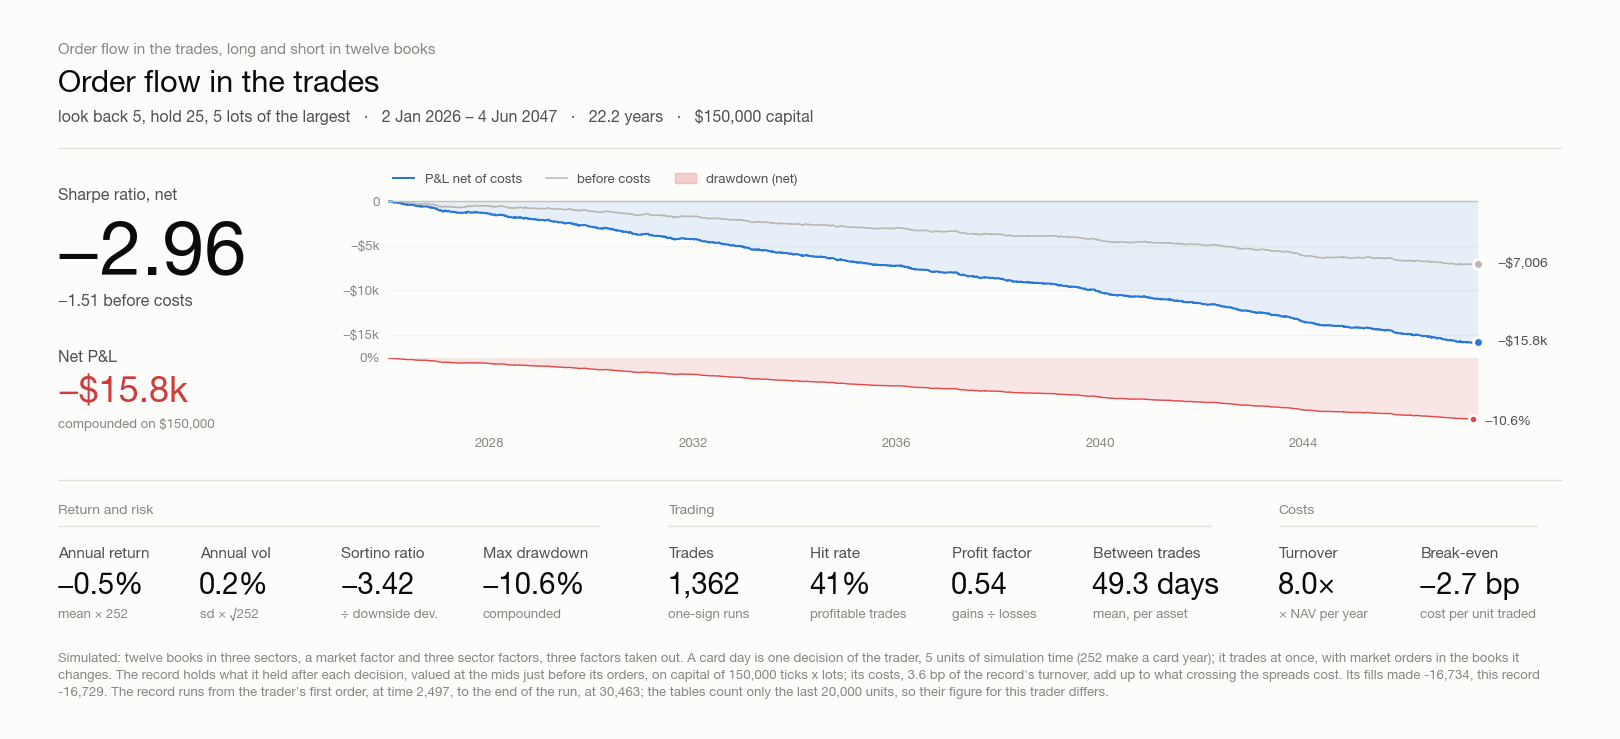

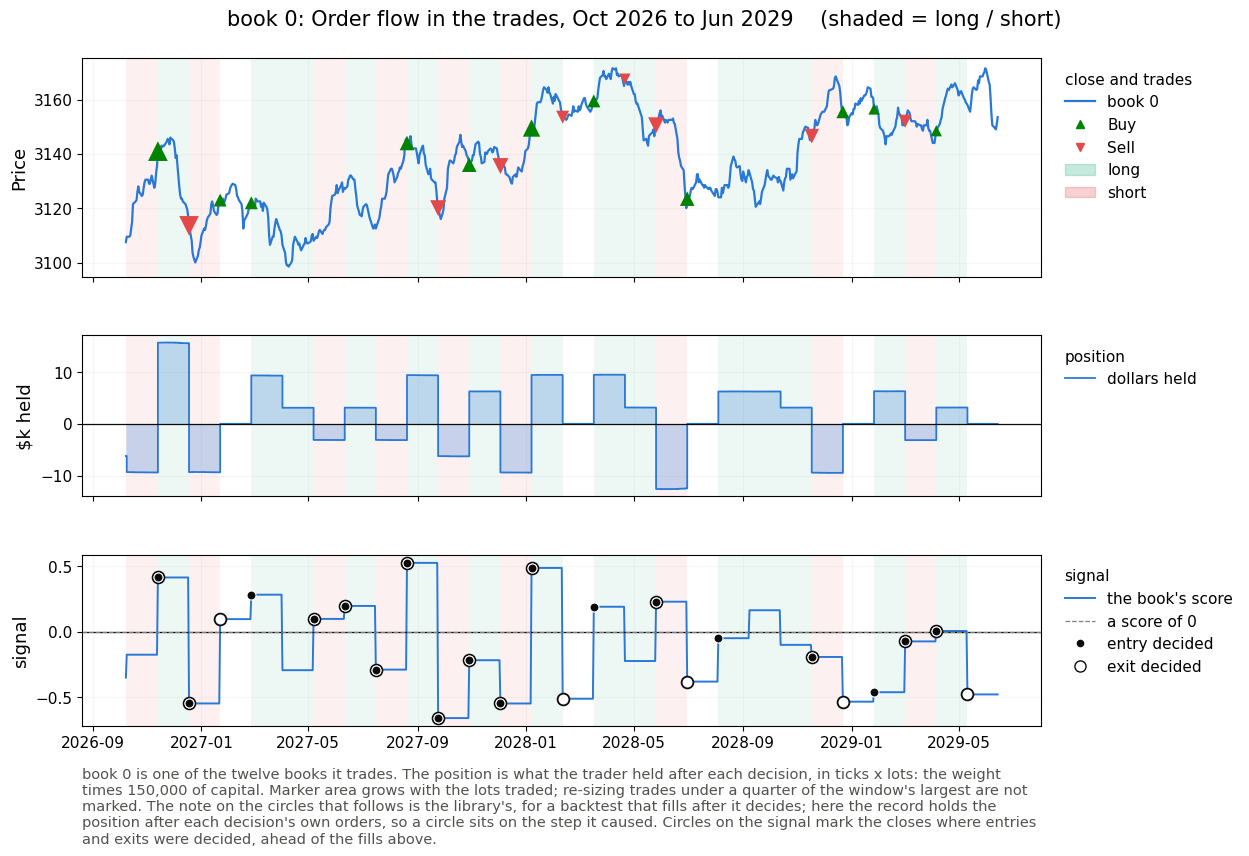

Each card against the fills, within what the run moves after its last decision: {'reversal': '+622 and +624', 'momentum': '-6,638 and -6,640', 'lead-lag': '-58,236 and -58,239', 'flow of queues': '-9,180 and -9,188', 'flow of trades': '-16,734 and -16,729'}
The most each card holds, as a multiple of the capital (above 1 the figure is leveraged): {'reversal': '0.82, above 1 on 0.0% of days', 'momentum': '0.85, above 1 on 0.0% of days', 'lead-lag': '0.98, above 1 on 0.0% of days', 'flow of queues': '0.99, above 1 on 0.0% of days', 'flow of trades': '0.80, above 1 on 0.0% of days'}
The tables' figure for these runs, the last 20,000 units only: {'reversal': '+67', 'momentum': '-5,134', 'lead-lag': '-39,432', 'flow of queues': '-7,385', 'flow of trades': '-12,297'}


In [5]:
CARDS = {
    'reversal': dict(
        trader='reversal, look back 20, hold 100, every 5',
        strategy='Cross-sectional reversal',
        detail='look back 20, hold 100, 5 lots of the largest',
        title='Reversal, long and short in twelve books',
        every=5,
    ),
    'momentum': dict(
        trader='momentum, look back 100, hold 100, every 5',
        strategy='Cross-sectional momentum',
        detail='look back 100, hold 100, 5 lots of the largest',
        title='Momentum, long and short in twelve books',
        every=5,
    ),
    'lead-lag': dict(
        trader='lead-lag, hold 20, every 1',
        strategy='Lead-lag',
        detail='ridge regression, hold 20, 5 lots of the largest',
        title='Lead-lag, long and short in twelve books',
        every=1,
    ),
    'flow of queues': dict(
        trader='flow of queues, hold 25, every 5',
        strategy='Order flow in the queues',
        detail='best bid against best ask, hold 25, 5 lots of the largest',
        title='Order flow in the queues, long and short in twelve books',
        every=5,
    ),
    'flow of trades': dict(
        trader='flow of trades, look back 5, hold 25, every 5',
        strategy='Order flow in the trades',
        detail='look back 5, hold 25, 5 lots of the largest',
        title='Order flow in the trades, long and short in twelve books',
        every=5,
    ),
}
SETTING = 'twelve books in three sectors, a market factor and three sector factors, three factors taken out'
runs_of_cards = Parallel(n_jobs=-1)(delayed(recorded)(TRADERS[form['trader']], BURN) for form in CARDS.values())
done = dict(zip(CARDS, runs_of_cards, strict=True))
agreement, peaks = {}, {}
for name, form in CARDS.items():
    trader, fills = done[name]
    held = np.array([step[2] for step in trader.history])
    book = int(np.argmax((np.diff(held, axis=0) != 0).sum(axis=0)))  # the book whose lots change most often
    gross = record_of(trader)[2].abs().sum(axis=1)  # what it holds, as a multiple of the capital
    peaks[name] = f'{gross.max():.2f}, above 1 on {(gross > 1).mean():.1%} of days'
    agreement[name] = card(
        trader,
        fills,
        form['strategy'],
        form['detail'],
        form['title'],
        SETTING,
        "the book's score",
        [(0.0, 'C7', 'a score of 0')],
        book,
        book,
        per_unit=form['every'],
    )
print(
    'Each card against the fills, within what the run moves after its last decision:',
    {k: f'{a:+,.0f} and {b:+,.0f}' for k, (a, b) in agreement.items()},
)
print('The most each card holds, as a multiple of the capital (above 1 the figure is leveraged):', peaks)
# The cards run from each trader's first order to the end; the tables count only the last SPAN units after the burn.
counted = {
    name: frame[(frame.market == 'sectors') & (frame.trader == form['trader']) & (frame.seed == SEEDS[0])].pnl.item()
    for name, form in CARDS.items()
}
print(
    f"The tables' figure for these runs, the last {SPAN:,.0f} units only:",
    {k: f'{v:+,.0f}' for k, v in counted.items()},
)

## 5. Conclusions

In [6]:
def said(r):
    return f'{r.pnl:+,.0f} (se {r.se:.0f}, {r.positive} seeds positive)'


def figures(mean, se, market, keys, column, digits=3):
    return ', '.join(
        f'{mean.loc[(market, key), column]:+.{digits}f} (se {se.loc[(market, key), column]:.{digits}f})' for key in keys
    )


def kind_of(name):
    return name.split(',')[0]


SHOWN = (1, 25, 100)
for market in MARKETS:
    print(
        f"- {market}, residual moves, a book's sum with its own next at {', '.join(map(str, SHOWN))} units: "
        f"{figures(memory_mean, memory_se, market, SHOWN, 'own')}; with another book's next: "
        f"{figures(memory_mean, memory_se, market, SHOWN, 'cross')}, of which the PCA forces "
        f"{figures(memory_mean, memory_se, market, SHOWN, 'forced')}, leaving "
        f"{figures(memory_mean, memory_se, market, SHOWN, 'beyond')}."
    )
for market in MARKETS:
    for lag in (LAGS[0], LAGS[-1]):
        part = 1000 * decomposition.loc[(market, lag)]
        print(
            f'- {market}, the contrarian portfolio at lag {lag}: {part.profit:+.2f} (se {part.se:.2f}) thousandths of '
            f'a tick a decision, of which own {part.own:+.2f}, cross {part.cross:+.2f}, means {part.means:+.2f}.'
        )
for market in MARKETS:
    rows = knows.loc[market]
    top = rows.sort_values('ic', ascending=False).head(3)
    best = '; '.join(f'{name} {r.ic:.3f} (edge {r.edge:+.4f})' for name, r in top.iterrows())
    kinds = crossing[crossing.market == market].set_index('kind')
    cost = '; '.join(f'{kind} {r.cost_a_lot:.2f}' for kind, r in kinds.iterrows())
    print(f'- {market}, what the signals know, by IC: {best}. A lot traded costs, in ticks: {cost}.')
    top = rows.per_lot.idxmax()
    print(
        f'  The most any listener earns a lot traded is {rows.per_lot.max():+.3f}, at {top} (turnover '
        f'{rows.turnover[top]:.2f} a decision, edge {rows.edge[top]:+.4f} a gross lot held), against the least cost of '
        f'{kinds.cost_a_lot.min():.2f} a lot traded.'
    )
for market in MARKETS:
    rows = table.loc[market]
    new = rows[~rows.index.isin(BASELINES)]
    by_kind = new.groupby(new.index.map(kind_of), sort=False)
    best, tried = by_kind.pnl.idxmax(), by_kind.size()
    print(
        f'- {market}, {(new.pnl > 0).sum()} of {len(new)} settings make money after costs, '
        f'{(new.pnl - 2 * new.se > 0).sum()} of them by two standard errors (counts over the list fixed in advance, '
        'not a test). The best of the few tried of each kind, on these seeds: '
        + '; '.join(f'{name} {said(new.loc[name])} (best of {tried[kind]})' for kind, name in best.items())
        + '.'
    )
    worst = new.pnl.idxmin()
    r = new.loc[worst]
    print(
        f'  The worst, {worst}, makes {said(r)}: {r.before_costs:+,.0f} before costs and {r.costs:,.0f} of costs, '
        f'{r.lots:,.0f} lots at {r.cost_a_lot:.2f} a lot.'
    )
    print('  Notebook 12 here: ' + '; '.join(f'{name} {said(rows.loc[name])}' for name in BASELINES) + '.')
print(
    'Each card against the fills:',
    {k: f'{a:+,.0f} and {b:+,.0f}' for k, (a, b) in agreement.items()},
)

- sectors, residual moves, a book's sum with its own next at 1, 25, 100 units: -0.159 (se 0.002), -0.045 (se 0.004), -0.344 (se 0.006); with another book's next: +0.014 (se 0.000), +0.004 (se 0.000), +0.031 (se 0.001), of which the PCA forces +0.014 (se 0.000), +0.004 (se 0.000), +0.031 (se 0.001), leaving -0.000 (se 0.000), -0.000 (se 0.000), -0.000 (se 0.000).
- mixed, residual moves, a book's sum with its own next at 1, 25, 100 units: -0.140 (se 0.001), -0.006 (se 0.005), -0.339 (se 0.007); with another book's next: +0.012 (se 0.000), +0.000 (se 0.000), +0.029 (se 0.001), of which the PCA forces +0.013 (se 0.000), +0.001 (se 0.000), +0.031 (se 0.001), leaving -0.001 (se 0.000), -0.000 (se 0.000), -0.002 (se 0.000).
- sectors, the contrarian portfolio at lag 1: +45.05 (se 1.63) thousandths of a tick a decision, of which own -19.44, cross +64.57, means -0.08.
- sectors, the contrarian portfolio at lag 25: +0.18 (se 0.34) thousandths of a tick a decision, of which own -4.02, cross +4.2

**Limitations.** There is one type of market here, twelve books with two tables of loadings, and the signals might behave differently in another. Every trader uses market orders only; passive orders could change every comparison that costs decide, and are where a signal that is right for a few units of time might pay. The signals' settings come from small grids on seeds 1 to 8, and a setting off those grids might do better. The best of a kind is the best of the few settings tried (up to three) on the same seeds that report it, and the counts of settings above two standard errors are counts over a list fixed in advance, so neither is a test. The before-cost figure at high turnover includes each trader's own impact on the mid it is marked at, so it is not the worth of a signal; section 2's listeners measure that without trading. The order flow is known exactly from the model, which says whether each order bought or sold, where a real trader infers the aggressor side from quotes and prints, with errors.